# M1: Storm Severity Predictor (XGBoost)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from xgboost import XGBRegressor

from solarshield.config import M1_MODEL_PATH
from solarshield.data.omni import load_omni
from solarshield.models.m1_storm import FEATURES, TARGET, build_dataset, metrics, split_by_year

## 1. Load OMNI data

In [2]:
df = load_omni()

print(df.shape)
print("Missing values per column:")
print(df.isna().sum())
df.describe().round(2)

(219168, 8)
Missing values per column:
year                 0
doy                  0
hour                 0
bz                 304
proton_density    4962
sw_speed           778
dyn_pressure      4970
dst                  0
dtype: int64


,year,doy,hour,bz,proton_density,sw_speed,dyn_pressure,dst
count,219168.00,219168.00,219168.00,218864.00,214206.00,218390.00,214198.00,219168.00
mean,2012.00,183.14,11.50,-0.02,6.00,427.72,1.94,-12.03
std,7.21,105.45,6.92,2.85,4.88,101.28,1.70,19.95
min,2000.00,1.00,0.00,-53.70,0.10,233.00,0.03,-422.00
25%,2006.00,92.00,5.75,-1.30,3.00,352.00,1.07,-19.00
50%,2012.00,183.00,11.50,0.00,4.60,405.00,1.54,-9.00
75%,2018.00,274.00,17.25,1.30,7.30,483.00,2.28,-1.00
max,2024.00,366.00,23.00,37.50,137.20,1189.00,71.04,77.00


## 2. Build features and target

In [3]:
data = build_dataset(df)   # dst_lag1 = Dst(t), dst_next = Dst(t+1)
print(f"{len(data):,} usable rows ({len(data) / len(df):.1%} of all hours)")

214,139 usable rows (97.7% of all hours)


## 3. Split by year (no shuffling, no leakage across time)

In [4]:
splits = split_by_year(data)
train, val, test = splits["train"], splits["val"], splits["test"]

for name, part in splits.items():
    print(f"{name:5s} {part.index.min():%Y-%m-%d} -> {part.index.max():%Y-%m-%d}  "
          f"{len(part):7,} rows ({len(part) / len(data):.1%})  min Dst = {part[TARGET].min():.0f} nT")

X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

train 2000-01-01 -> 2016-12-31  144,811 rows (67.6%)  min Dst = -422 nT
val   2017-01-01 -> 2020-12-31   34,988 rows (16.3%)  min Dst = -176 nT
test  2021-01-01 -> 2024-12-31   34,340 rows (16.0%)  min Dst = -406 nT


## 4. Train XGBoost (plan defaults)

### 4a. Plan model: target = Dst(t+1)

In [5]:
model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
)
model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=100)

[0]	validation_0-rmse:18.56586	validation_1-rmse:12.35197


[100]	validation_0-rmse:3.68556	validation_1-rmse:3.08825


[200]	validation_0-rmse:3.46567	validation_1-rmse:3.08766


[300]	validation_0-rmse:3.34206	validation_1-rmse:3.09633


[400]	validation_0-rmse:3.26073	validation_1-rmse:3.10110


[499]	validation_0-rmse:3.18067	validation_1-rmse:3.10637


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


### 4b. Delta model: target = Dst(t+1) − Dst(t)

In [6]:
delta_model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
)
delta_model.fit(
    X_train, y_train - X_train["dst_lag1"],
    eval_set=[(X_train, y_train - X_train["dst_lag1"]), (X_val, y_val - X_val["dst_lag1"])],
    verbose=100,
)

def predict_dst_next(X):
    """Delta model forecast of Dst at t+1 (nT)."""
    return delta_model.predict(X[FEATURES]) + X["dst_lag1"].to_numpy()

[0]	validation_0-rmse:4.26747	validation_1-rmse:3.32017


[100]	validation_0-rmse:3.38821	validation_1-rmse:3.01593


[200]	validation_0-rmse:3.29180	validation_1-rmse:3.02467


[300]	validation_0-rmse:3.21355	validation_1-rmse:3.03206


[400]	validation_0-rmse:3.15605	validation_1-rmse:3.03733


[499]	validation_0-rmse:3.10164	validation_1-rmse:3.04168


## 5. Evaluate

In [7]:
rows = {}
for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    storm = (y < -50).to_numpy()
    preds = {
        "plan model": model.predict(X),
        "delta model": predict_dst_next(X),
        "persistence": X["dst_lag1"].to_numpy(),
    }
    for label, pred in preds.items():
        rows[(name, "all hours", label)] = metrics(y, pred)
        rows[(name, "storm hours (Dst<-50)", label)] = metrics(y[storm], pred[storm])

results = pd.DataFrame(rows).T.round(3)
results

R2  MAE (nT)  RMSE (nT)
train all hours             plan model   0.976     2.268      3.181
      storm hours (Dst<-50) plan model   0.972     4.360      5.929
      all hours             delta model  0.977     2.233      3.102
      storm hours (Dst<-50) delta model  0.978     3.928      5.260
      all hours             persistence  0.954     2.713      4.382
      storm hours (Dst<-50) persistence  0.888     7.188     11.795
val   all hours             plan model   0.943     2.159      3.106
      storm hours (Dst<-50) plan model   0.787     6.991     10.563
      all hours             delta model  0.945     2.150      3.042
      storm hours (Dst<-50) delta model  0.859     6.262      8.596
      all hours             persistence  0.933     2.296      3.371
      storm hours (Dst<-50) persistence  0.808     7.310     10.019
test  all hours             plan model   0.942     2.698      5.076
      storm hours (Dst<-50) plan model   0.821     9.487     20.300
      all hours             delta model  0.965     2.587      3.951
      storm hours (Dst<-50) delta model  0.951     6.418     10.579
      all hours             persistence  0.953     2.885      4.579
      storm hours (Dst<-50) persistence  0.930     7.864     12.730

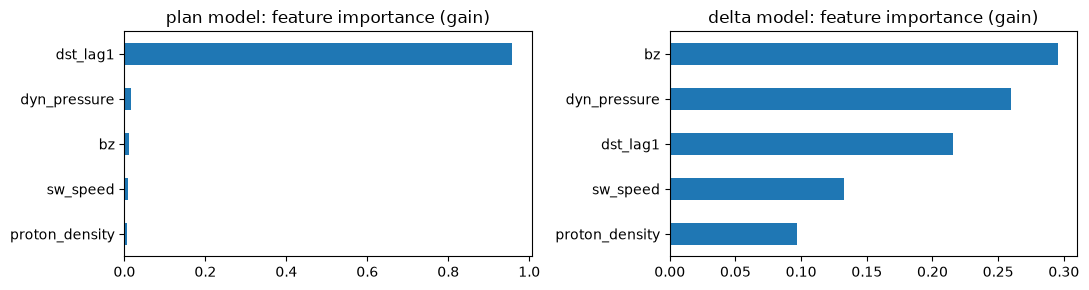

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, (label, m) in zip(axes, [("plan model", model), ("delta model", delta_model)]):
    pd.Series(m.feature_importances_, index=FEATURES).sort_values().plot.barh(ax=ax)
    ax.set_title(f"{label}: feature importance (gain)")
plt.tight_layout()
plt.show()

## 6. Case study: May 2024 superstorm (test set)

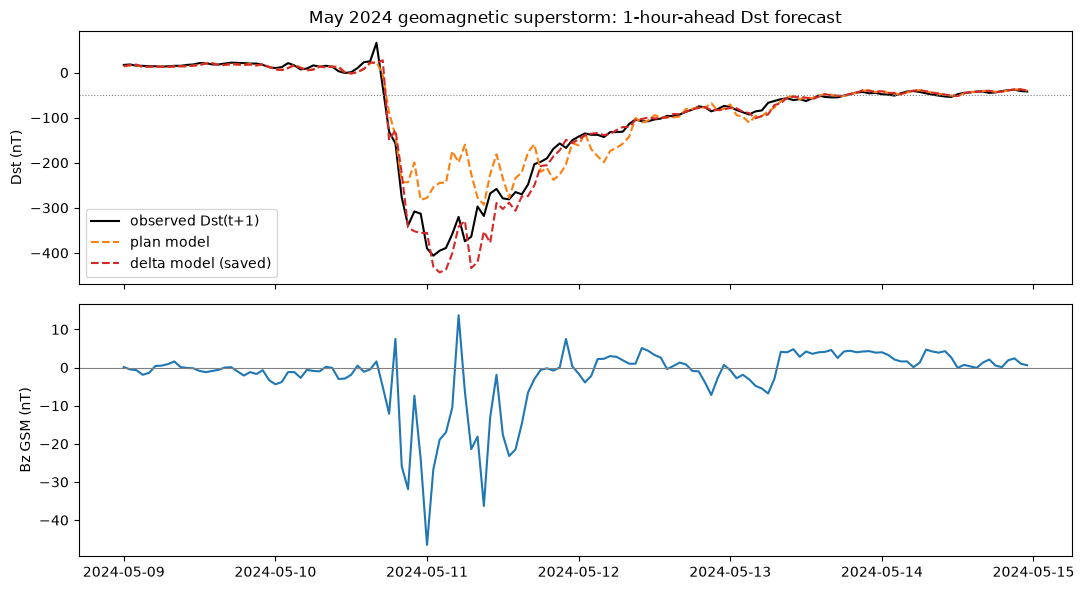

Observed min Dst: -406 nT
Plan model min:   -293 nT
Delta model min:  -443 nT


,R2,MAE (nT),RMSE (nT)
plan model,0.85,20.69,43.30
delta model,0.96,11.10,21.81
persistence,0.96,10.13,21.67


In [9]:
window = test.loc["2024-05-09":"2024-05-14"]
pred = pd.Series(model.predict(window[FEATURES]), index=window.index)
pred_delta = pd.Series(predict_dst_next(window), index=window.index)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(window.index, window[TARGET], label="observed Dst(t+1)", color="black")
axes[0].plot(window.index, pred, label="plan model", color="tab:orange", linestyle="--")
axes[0].plot(window.index, pred_delta, label="delta model (saved)", color="tab:red", linestyle="--")
axes[0].axhline(-50, color="grey", lw=0.8, ls=":")
axes[0].set_ylabel("Dst (nT)")
axes[0].legend()
axes[0].set_title("May 2024 geomagnetic superstorm: 1-hour-ahead Dst forecast")
axes[1].plot(window.index, window["bz"], color="tab:blue")
axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set_ylabel("Bz GSM (nT)")
plt.tight_layout()
plt.show()

print(f"Observed min Dst: {window[TARGET].min():.0f} nT")
print(f"Plan model min:   {pred.min():.0f} nT")
print(f"Delta model min:  {pred_delta.min():.0f} nT")
pd.DataFrame({
    "plan model": metrics(window[TARGET], pred),
    "delta model": metrics(window[TARGET], pred_delta),
    "persistence": metrics(window[TARGET], window["dst_lag1"]),
}).T.round(2)

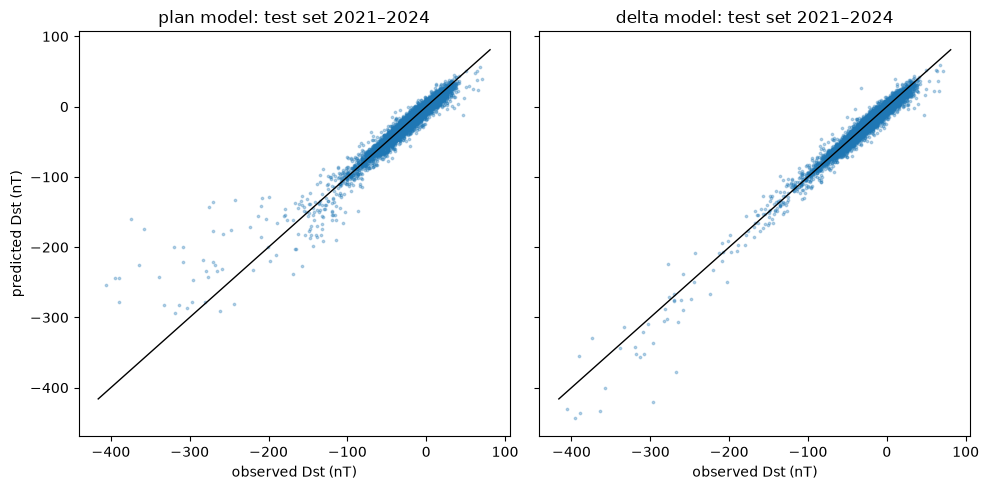

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
lims = [y_test.min() - 10, y_test.max() + 10]
for ax, (label, test_pred) in zip(axes, [("plan model", model.predict(X_test)), ("delta model", predict_dst_next(X_test))]):
    ax.scatter(y_test, test_pred, s=3, alpha=0.3)
    ax.plot(lims, lims, color="black", lw=1)
    ax.set_xlabel("observed Dst (nT)")
    ax.set_title(f"{label}: test set 2021–2024")
axes[0].set_ylabel("predicted Dst (nT)")
plt.tight_layout()
plt.show()

## 7. Save the model

```python
bundle = joblib.load("models/m1_xgb.pkl")
X = df[bundle["features"]]   # bz, proton_density, sw_speed, dyn_pressure, dst_lag1 (all at hour t)
dst_next = bundle["model"].predict(X) + X["dst_lag1"]   # Dst at hour t+1 (nT)
```

In [11]:
bundle = {
    "model": delta_model,
    "features": FEATURES,
    "target": "Dst(t+1) - Dst(t) in nT; add dst_lag1 to get Dst at t+1",
    "predicts_delta": True,
    "train_years": "2000-2016",
    "test_metrics": rows[("test", "all hours", "delta model")],
    "test_storm_metrics": rows[("test", "storm hours (Dst<-50)", "delta model")],
}
joblib.dump(bundle, M1_MODEL_PATH)

loaded = joblib.load(M1_MODEL_PATH)
example = pd.DataFrame([{"bz": -15.0, "proton_density": 20.0, "sw_speed": 650.0, "dyn_pressure": 12.0, "dst_lag1": -80.0}])
print("Saved to", M1_MODEL_PATH)
dst_next = loaded["model"].predict(example[loaded["features"]]) + example["dst_lag1"].to_numpy()
print("Example storm input -> predicted Dst(t+1):", round(float(dst_next[0]), 1), "nT")

Saved to models/m1_xgb.pkl
Example storm input -> predicted Dst(t+1): -123.6 nT
